# Dear Canada — Diary Generation Pipeline

This notebook trains two generative models on the Dear Canada book series and compares their ability to produce historically grounded, first-person diary entries conditioned on a **date**, **topic**, and **sentiment**.

| Model | Description |
|---|---|
| **From-scratch decoder transformer** | GPT-style architecture trained entirely on the diary corpus with a custom BPE tokenizer |
| **Fine-tuned DistilGPT-2** | Pretrained language model adapted to diary style via fine-tuning |

Sentiment conditioning reuses the classifier pipeline developed in the previous assignment: entries are labelled with their dominant sentiment, and a `[SENTIMENT:]` token is prepended at training time so the model learns to condition on it at inference.

---

## Section 1 — Load & Normalise Entry Data

In [1]:
import pandas as pd
import glob
import os
import re
import math
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ── Load all per-book entry CSVs ──────────────────────────────────────────────
entry_files = glob.glob("dataframes/untagged/all_books_entry_dfs/*.csv")

entries = pd.concat(
    [pd.read_csv(f) for f in entry_files], ignore_index=True
)
entries = entries.dropna(subset=["entry_text"])
entries = entries[entries["entry_text"].str.strip().str.len() > 50]

print(f"Total entries loaded: {len(entries)}")
print(f"Books ({len(entries['book'].unique())}): {sorted(entries['book'].unique())}")

Total entries loaded: 3159
Books (20): ['AToBD', 'AinUTL', 'BFfH', 'BUoL', 'CofOO', 'DRtoF', 'DofTT', 'DofmyC', 'EftW', 'FitS', 'NSH', 'NbutC', 'OA', 'OatmyD', 'PasWide', 'PintPL', 'SofS', 'TA', 'TFN', 'WofW']


In [2]:
# ── Date normalisation ────────────────────────────────────────────────────────
# Each book uses a different date format. All are normalised to 'Month DD, YYYY'.
# Where the date is partial (no year), the book's known historical year is used.

FR_MONTHS = {
    "janvier": "January", "février": "February", "fevrier": "February",
    "mars": "March", "avril": "April", "mai": "May", "juin": "June",
    "juillet": "July", "août": "August", "aout": "August",
    "septembre": "September", "octobre": "October",
    "novembre": "November", "décembre": "December", "decembre": "December"
}
EN_MONTHS = [
    "January","February","March","April","May","June",
    "July","August","September","October","November","December"
]

# Known historical year per book — used to fill partial dates
DEFAULT_YEARS = {
    "AinUTL": 1666, "AToBD": 1862, "BFfH": 1916, "BUoL": 1885,
    "CofOO": 1866, "DofmyC": 1759, "DofTT": 1887, "DRtoF": 1863,
    "EftW": 1940, "FitS": 1815, "NbutC": 1783, "NSH": 1917,
    "OA": 1922, "OatmyD": 1897, "PasWide": 1926, "PintPL": 1914,
    "SofS": 1847, "TA": 1941, "TFN": 1912, "WofW": 1812
}

def normalise_date(raw: str, default_year: int | None = None) -> str:
    if not isinstance(raw, str):
        return "Unknown Date"
    s = raw.strip()

    fr = re.search(r"le\s+(\d{1,2})\s+(" + "|".join(FR_MONTHS) + r")\s+(\d{4})", s, re.I)
    if fr:
        return f"{FR_MONTHS[fr.group(2).lower()]} {fr.group(1).zfill(2)}, {fr.group(3)}"

    dmy = re.search(r"(\d{1,2})\s+(" + "|".join(EN_MONTHS) + r")\s+(\d{4})", s, re.I)
    if dmy:
        return f"{dmy.group(2).capitalize()} {dmy.group(1).zfill(2)}, {dmy.group(3)}"

    mdy = re.search(r"(" + "|".join(EN_MONTHS) + r")\s+(\d{1,2})(?:st|nd|rd|th)?[,\s]+(\d{4})", s, re.I)
    if mdy:
        return f"{mdy.group(1).capitalize()} {mdy.group(2).zfill(2)}, {mdy.group(3)}"

    wd = re.search(r"(?:Mon|Tue|Wed|Thu|Fri|Sat|Sun)[a-z]*,?\s*(" + "|".join(EN_MONTHS) + r")\s+(\d{1,2})", s, re.I)
    if wd:
        m, d = wd.group(1).capitalize(), wd.group(2).zfill(2)
        return f"{m} {d}, {default_year}" if default_year else f"{m} {d}"

    md = re.search(r"(" + "|".join(EN_MONTHS) + r")\s+(\d{1,2})\b", s, re.I)
    if md:
        m, d = md.group(1).capitalize(), md.group(2).zfill(2)
        return f"{m} {d}, {default_year}" if default_year else f"{m} {d}"

    my = re.search(r"(" + "|".join(EN_MONTHS) + r")\s+(\d{4})", s, re.I)
    if my:
        return f"{my.group(1).capitalize()} {my.group(2)}"

    yr = re.search(r"\b(1[5-9]\d{2})\b", s)
    if yr:
        return yr.group(1)

    return s


entries["default_year"]    = entries["book"].map(DEFAULT_YEARS)
entries["date_normalised"] = entries.apply(
    lambda r: normalise_date(r["date"], r["default_year"]), axis=1
)

# Fill any remaining dates that still lack a year
mask = ~entries["date_normalised"].str.contains(r"\b\d{4}\b", na=False)
entries.loc[mask, "date_normalised"] = (
    entries.loc[mask, "date_normalised"] + ", " +
    entries.loc[mask, "default_year"].astype("Int64").astype(str)
)

print(entries[["book","date","date_normalised"]].groupby("book").head(1).to_string())

         book                              date     date_normalised
0       AToBD                      May 15, 1862        May 15, 1862
114      FitS                           July 15       July 15, 1815
257     DRtoF  Saturday, January 10\nth\n, 1863    January 10, 1863
457      BFfH                 December 25, 1916   December 25, 1916
591        TA            Saturday, May 24, 1941        May 24, 1941
865      EftW             Monday, June 17, 1940       June 17, 1940
1124    NbutC                 October 6th, 1783    October 06, 1783
1279     SofS                    April 30, 1847      April 30, 1847
1416      TFN                       May 1, 1912        May 01, 1912
1486   DofmyC                   Le 8 avril 1759      April 08, 1759
1661   PintPL            Monday, April 13, 1914      April 13, 1914
1891    DofTT                      May 19, 1887        May 19, 1887
2060     WofW                       10 May 1812        May 10, 1812
2199     BUoL               Le 31 décembre 1884 

## Section 2 — Sentiment Labelling

Sentiment scores were produced by the ensemble classifier from the previous assignment and saved per-book to `dataframes/untagged/sentiment_scored_entries_dfs/`. Each entry is labelled with the model's predicted dominant sentiment (positive, negative, or neutral), which becomes a conditioning token during training.

This allows the generator to be steered toward a particular emotional register at inference time — the model learns, for example, that `[SENTIMENT: negative]` entries tend to describe grief, hardship, and loss.

In [3]:
# ── Load sentiment scores and join to entries ─────────────────────────────────
sent_files = glob.glob("dataframes/untagged/sentiment_scored_entries_dfs/*.csv")

sentiment_df = pd.concat(
    [pd.read_csv(f) for f in sent_files], ignore_index=True
)

# Keep only the columns we need for joining
sentiment_df = sentiment_df[[
    "book", "entry_id",
    "Positive_score", "Negative_score", "Neutral_score"
]].drop_duplicates(subset=["book","entry_id"])

entries = entries.merge(sentiment_df, on=["book","entry_id"], how="left")

# ── Assign dominant sentiment label ──────────────────────────────────────────
# Where all three scores are available, take the argmax.
# Entries without a sentiment score (books not yet passed through the classifier)
# are labelled 'neutral' as a conservative default.

score_cols = ["Positive_score", "Negative_score", "Neutral_score"]
label_map  = {0: "positive", 1: "negative", 2: "neutral"}

has_scores = entries[score_cols].notna().all(axis=1)

entries.loc[has_scores, "sentiment"] = (
    entries.loc[has_scores, score_cols]
    .values.argmax(axis=1)
)
entries["sentiment"] = (
    entries["sentiment"].map(label_map).fillna("neutral")
)

print("Sentiment distribution:")
print(entries["sentiment"].value_counts())
print(f"\nEntries with scores: {has_scores.sum()} / {len(entries)}")

Sentiment distribution:
sentiment
neutral     1260
negative    1247
positive     652
Name: count, dtype: int64

Entries with scores: 2768 / 3159


## Section 3 — Build Training Corpus

Each training example is formatted as:

```
[DATE: March 14, 1847] [TOPIC: hunger cold voyage death] [SENTIMENT: negative] <entry text> <|endofentry|>
```

Topics are extracted automatically per entry via TF-IDF — no manual labelling required.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

TOPIC_WORDS = 4

vectorizer = TfidfVectorizer(
    max_features=3000, stop_words="english", ngram_range=(1,1), min_df=2
)
tfidf_matrix  = vectorizer.fit_transform(entries["entry_text"])
feature_names = vectorizer.get_feature_names_out()

def extract_topic(row_idx: int, n: int = TOPIC_WORDS) -> str:
    row    = tfidf_matrix[row_idx]
    top    = sorted(zip(row.indices, row.data), key=lambda x: x[1], reverse=True)[:n]
    return " ".join(feature_names[i] for i, _ in top)

entries["topic"] = [extract_topic(i) for i in range(len(entries))]

print("Sample topics:")
print(entries[["book","date_normalised","sentiment","topic"]].head(8).to_string())

Sample topics:
    book date_normalised sentiment                            topic
0  AToBD    May 15, 1862  negative  account bent filling settlement
1  AToBD    May 15, 1862  negative       owen mama belong searching
2  AToBD    May 17, 1862  negative         money fields gold father
3  AToBD    May 18, 1862  negative         work tried barracks maid
4  AToBD    May 20, 1862  negative        luella bags rooms william
5  AToBD    May 22, 1862  positive          owen luella mrs william
6  AToBD    May 24, 1862   neutral       marched parade queen drink
7  AToBD    May 25, 1862  negative           letter send cried mama


In [5]:
# ── Format entries ────────────────────────────────────────────────────────────
END_TOKEN = "<|endofentry|>"

def format_entry(row) -> str:
    return (
        f"[DATE: {row['date_normalised']}] "
        f"[TOPIC: {row['topic']}] "
        f"[SENTIMENT: {row['sentiment']}] "
        f"{row['entry_text'].strip()} "
        f"{END_TOKEN}"
    )

entries["formatted"] = entries.apply(format_entry, axis=1)

In [6]:
# ── Validation split ──────────────────────────────────────────────────────────
# Strategy: hold out one book entirely (unseen style) + 25% of entries from
# four other books. This creates a validation set that tests generalisation
# across styles without the model being able to memorise any single book completely.

import random
random.seed(42)

all_books       = sorted(entries["book"].unique())
holdout_book    = "PasWide"   # held out entirely — withheld style
partial_books   = random.sample([b for b in all_books if b != holdout_book], 4)
PARTIAL_VAL_FRAC = 0.25

val_idx_list = []

# Full holdout book
val_idx_list.append(entries[entries["book"] == holdout_book].index)

# 25% sample from four other books
for book in partial_books:
    book_idx = entries[entries["book"] == book].index
    sample   = book_idx[: int(len(book_idx) * PARTIAL_VAL_FRAC)]
    val_idx_list.append(sample)

val_idx   = np.concatenate([i.to_numpy() for i in val_idx_list])
train_idx = np.setdiff1d(entries.index.to_numpy(), val_idx)

train_entries = entries.loc[train_idx].reset_index(drop=True)
val_entries   = entries.loc[val_idx].reset_index(drop=True)

print(f"Train: {len(train_entries)} entries | Val: {len(val_entries)} entries")
print(f"Held-out book (entirely): {holdout_book}")
print(f"Partially held-out books: {partial_books}")
print("\nVal distribution:")
print(val_entries["book"].value_counts())

os.makedirs("dataframes/corpus", exist_ok=True)
train_entries["formatted"].to_csv("dataframes/corpus/train.txt", index=False, header=False)
val_entries["formatted"].to_csv("dataframes/corpus/val.txt",   index=False, header=False)
print("\nCorpus saved.")

Train: 2805 entries | Val: 354 entries
Held-out book (entirely): PasWide
Partially held-out books: ['BUoL', 'AToBD', 'EftW', 'DofmyC']

Val distribution:
book
PasWide    191
EftW        63
DofmyC      42
BUoL        31
AToBD       27
Name: count, dtype: int64

Corpus saved.


## Section 4 — BPE Tokenizer

A Byte-Pair Encoding tokenizer is trained from scratch on the diary corpus. This gives the from-scratch model a vocabulary tuned to 19th-century language and the series' specific vocabulary, rather than modern web text. DistilGPT-2 uses its own pretrained tokenizer.

In [7]:
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import ByteLevel
from tokenizers.decoders import ByteLevel as ByteLevelDecoder

VOCAB_SIZE     = 8000
special_tokens = ["<|pad|>", "<|unk|>", "<|endofentry|>", "[DATE:", "[TOPIC:", "[SENTIMENT:"]

tokenizer = Tokenizer(BPE(unk_token="<|unk|>"))
tokenizer.pre_tokenizer = ByteLevel(add_prefix_space=True)
tokenizer.decoder       = ByteLevelDecoder()

trainer = BpeTrainer(
    vocab_size=VOCAB_SIZE, special_tokens=special_tokens,
    min_frequency=2, show_progress=True
)
tokenizer.train(
    files=["dataframes/corpus/train.txt", "dataframes/corpus/val.txt"],
    trainer=trainer
)

os.makedirs("models/tokenizer", exist_ok=True)
tokenizer.save("models/tokenizer/bpe_tokenizer.json")

PAD_ID = tokenizer.token_to_id("<|pad|>")
EOE_ID = tokenizer.token_to_id("<|endofentry|>")

print(f"Vocab size: {tokenizer.get_vocab_size()}")
print(f"PAD id: {PAD_ID} | EOE id: {EOE_ID}")

sample_enc = tokenizer.encode(train_entries["formatted"].iloc[0])
print(f"Sample entry token count: {len(sample_enc.ids)}")




Vocab size: 8000
PAD id: 0 | EOE id: 2
Sample entry token count: 199


In [8]:
from torch.utils.data import Dataset, DataLoader

CONTEXT_LEN = 128

class DiaryDataset(Dataset):
    """
    Sliding-window dataset over the full tokenised corpus.
    Each item is a (context_len,) input window; the target is the
    same window shifted one position right (next-token prediction).
    """
    def __init__(self, texts: list[str], tokenizer, context_len: int):
        all_ids = []
        for text in texts:
            all_ids.extend(tokenizer.encode(text).ids)
        self.ids         = torch.tensor(all_ids, dtype=torch.long)
        self.context_len = context_len

    def __len__(self):         return len(self.ids) - self.context_len
    def __getitem__(self, idx):
        x = self.ids[idx : idx + self.context_len]
        y = self.ids[idx + 1 : idx + self.context_len + 1]
        return x, y

train_dataset = DiaryDataset(train_entries["formatted"].tolist(), tokenizer, CONTEXT_LEN)
val_dataset   = DiaryDataset(val_entries["formatted"].tolist(),   tokenizer, CONTEXT_LEN)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False)

print(f"Train tokens: {len(train_dataset.ids):,}")
print(f"Val tokens:   {len(val_dataset.ids):,}")

Train tokens: 927,466
Val tokens:   120,432


## Section 5 — From-Scratch Decoder Transformer

A GPT-style decoder-only transformer: learned token and positional embeddings, $N$ causal self-attention layers, and a tied output projection. The causal mask ensures each position can only attend to preceding tokens, making the architecture a decoder rather than an encoder.

**Architecture** (balanced for quality vs. training time on CPU/MPS):

| Hyperparameter | Value |
|---|---|
| Layers | 4 |
| Attention heads | 4 |
| Embedding dim | 128 |
| FFN hidden dim | 512 |
| Context window | 128 tokens |
| Parameters | ~4M |

In [10]:
class CausalSelfAttention(nn.Module):
    """
    Multi-head causal self-attention. The upper-triangular mask prevents
    each token from attending to future positions, which is what makes
    this a generative (decoder) architecture.
    """
    def __init__(self, d_model: int, n_heads: int, dropout: float = 0.1):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.d_head  = d_model // n_heads
        self.qkv     = nn.Linear(d_model, 3 * d_model, bias=False)
        self.out     = nn.Linear(d_model, d_model, bias=False)
        self.drop    = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        qkv = self.qkv(x).reshape(B, T, 3, self.n_heads, self.d_head).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = (q @ k.transpose(-2, -1)) / math.sqrt(self.d_head)
        mask = torch.triu(torch.ones(T, T, device=x.device), diagonal=1).bool()
        attn = attn.masked_fill(mask, float("-inf"))
        attn = self.drop(torch.softmax(attn, dim=-1))
        return self.out((attn @ v).transpose(1, 2).reshape(B, T, C))


class TransformerBlock(nn.Module):
    """Pre-norm transformer block: LayerNorm → attention → residual, LayerNorm → FFN → residual."""
    def __init__(self, d_model, n_heads, ffn_dim, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attn  = CausalSelfAttention(d_model, n_heads, dropout)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn   = nn.Sequential(
            nn.Linear(d_model, ffn_dim), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(ffn_dim, d_model), nn.Dropout(dropout),
        )
    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        x = x + self.ffn(self.norm2(x))
        return x


class DiaryTransformer(nn.Module):
    """
    GPT-style decoder. Input: (B, T) token IDs. Output: (B, T, vocab_size) logits.
    Weight tying between token embeddings and the output projection reduces
    parameters and encourages a shared representation space (Press & Wolf, 2017).
    """
    def __init__(self, vocab_size, d_model=128, n_heads=4, n_layers=4,
                 context_len=128, ffn_dim=512, dropout=0.15):
        super().__init__()
        self.context_len = context_len
        self.tok_emb  = nn.Embedding(vocab_size, d_model)
        self.pos_emb  = nn.Embedding(context_len, d_model)
        self.drop     = nn.Dropout(dropout)
        self.blocks   = nn.Sequential(*[TransformerBlock(d_model, n_heads, ffn_dim, dropout) for _ in range(n_layers)])
        self.norm     = nn.LayerNorm(d_model)
        self.lm_head  = nn.Linear(d_model, vocab_size, bias=False)
        self.lm_head.weight = self.tok_emb.weight  # weight tying
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0.0, 0.02)
                if m.bias is not None: nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Embedding):
                nn.init.normal_(m.weight, 0.0, 0.02)

    def forward(self, x):
        B, T = x.shape
        pos  = torch.arange(T, device=x.device).unsqueeze(0)
        x    = self.drop(self.tok_emb(x) + self.pos_emb(pos))
        return self.lm_head(self.norm(self.blocks(x)))

    @torch.no_grad()
    def generate(self, prompt_ids, max_new_tokens=200, temperature=0.9, top_k=50, eoe_id=None):
        """
        Top-k sampling with temperature. temperature < 1 is more conservative;
        top_k limits sampling to the k most probable tokens at each step.
        """
        self.eval()
        ids = prompt_ids.clone()
        for _ in range(max_new_tokens):
            logits = self(ids[:, -self.context_len:])[:, -1, :] / temperature
            if top_k:
                v, _ = torch.topk(logits, top_k)
                logits = logits.masked_fill(logits < v[:, -1:], float("-inf"))
            next_id = torch.multinomial(torch.softmax(logits, -1), 1)
            ids = torch.cat([ids, next_id], dim=1)
            if eoe_id is not None and next_id.item() == eoe_id:
                break
        return ids


DEVICE = torch.device("cuda" if torch.cuda.is_available() else
                      "mps"  if torch.backends.mps.is_available() else "cpu")
print(f"Device: {DEVICE}")

scratch_model = DiaryTransformer(
    vocab_size=tokenizer.get_vocab_size(),
    d_model=128,
    n_heads=4,
    n_layers=4,
    context_len=CONTEXT_LEN, 
    ffn_dim=512,
    dropout=0.15
).to(DEVICE)

print(f"Parameters: {sum(p.numel() for p in scratch_model.parameters()):,}")

Device: mps
Parameters: 1,831,680


In [11]:
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

EPOCHS = 3
LR     = 3e-4

optimizer = AdamW(scratch_model.parameters(), lr=LR, weight_decay=0.01)
scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)

os.makedirs("models/scratch",  exist_ok=True)
os.makedirs("figures",         exist_ok=True)

train_losses, val_losses = [], []
best_val = float("inf")

for epoch in range(1, EPOCHS + 1):
    scratch_model.train()
    total = 0.0
    for i, (x, y) in enumerate(train_loader):
        if i % 500 == 0:
            print(f"Batch {i}/{len(train_loader)}")
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(scratch_model(x).reshape(-1, tokenizer.get_vocab_size()), y.reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(scratch_model.parameters(), 1.0)
        optimizer.step()
        total += loss.item()
    scheduler.step()
    avg_tr = total / len(train_loader)
    train_losses.append(avg_tr)

    scratch_model.eval()
    total = 0.0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            total += criterion(scratch_model(x).reshape(-1, tokenizer.get_vocab_size()), y.reshape(-1)).item()
    avg_val = total / len(val_loader)
    val_losses.append(avg_val)

    if avg_val < best_val:
        best_val = avg_val
        torch.save(scratch_model.state_dict(), "models/scratch/best_model.pt")

    #if epoch % 5 == 0 or epoch == 1:
    print(f"Epoch {epoch:3d}/{EPOCHS} | train {avg_tr:.4f} | val {avg_val:.4f} | ppl {math.exp(avg_val):.1f}")

print(f"\nBest val loss: {best_val:.4f} | PPL: {math.exp(best_val):.1f}")

Batch 0/28980
Batch 500/28980
Batch 1000/28980
Batch 1500/28980
Batch 2000/28980
Batch 2500/28980
Batch 3000/28980
Batch 3500/28980
Batch 4000/28980
Batch 4500/28980
Batch 5000/28980
Batch 5500/28980
Batch 6000/28980
Batch 6500/28980
Batch 7000/28980
Batch 7500/28980
Batch 8000/28980
Batch 8500/28980
Batch 9000/28980
Batch 9500/28980
Batch 10000/28980
Batch 10500/28980
Batch 11000/28980
Batch 11500/28980
Batch 12000/28980
Batch 12500/28980
Batch 13000/28980
Batch 13500/28980
Batch 14000/28980
Batch 14500/28980
Batch 15000/28980
Batch 15500/28980
Batch 16000/28980
Batch 16500/28980
Batch 17000/28980
Batch 17500/28980
Batch 18000/28980
Batch 18500/28980
Batch 19000/28980
Batch 19500/28980
Batch 20000/28980
Batch 20500/28980
Batch 21000/28980
Batch 21500/28980
Batch 22000/28980
Batch 22500/28980
Batch 23000/28980
Batch 23500/28980
Batch 24000/28980
Batch 24500/28980
Batch 25000/28980
Batch 25500/28980
Batch 26000/28980
Batch 26500/28980
Batch 27000/28980
Batch 27500/28980
Batch 28000/2898

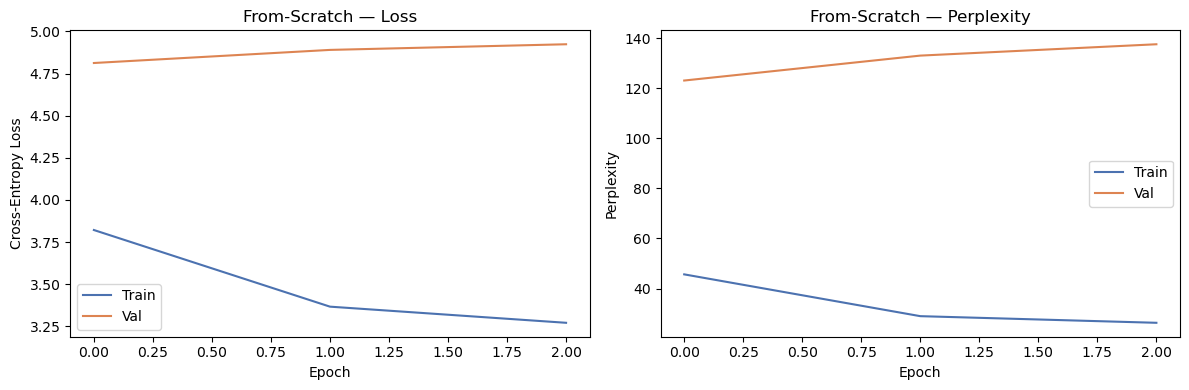

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, vals, title, ylabel in [
    (axes[0], (train_losses, val_losses), "From-Scratch — Loss",       "Cross-Entropy Loss"),
    (axes[1], ([math.exp(l) for l in train_losses], [math.exp(l) for l in val_losses]),
               "From-Scratch — Perplexity", "Perplexity"),
]:
    ax.plot(vals[0], label="Train", color="#4C72B0")
    ax.plot(vals[1], label="Val",   color="#DD8452")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel); ax.legend()
plt.tight_layout()
plt.savefig("figures/scratch_training_curves.png", dpi=150)
plt.show()

## Section 6 — Fine-tuned DistilGPT-2

DistilGPT-2 is a 6-layer, 82M-parameter distilled version of GPT-2 small, pretrained on WebText. Fine-tuning adapts its weights to the diary domain using the same prompt format as the from-scratch model, keeping the two directly comparable. The `[SENTIMENT:]` token is added to the tokenizer vocabulary so the model can learn to condition on it.

In [13]:
from transformers import (
    AutoTokenizer, AutoModelForCausalLM,
    TrainingArguments, Trainer, DataCollatorForLanguageModeling
)
from datasets import Dataset as HFDataset

gpt2_tokenizer = AutoTokenizer.from_pretrained("distilgpt2")
gpt2_tokenizer.pad_token = gpt2_tokenizer.eos_token
gpt2_tokenizer.add_special_tokens({
    "additional_special_tokens": ["<|endofentry|>", "[SENTIMENT:"]
})

gpt2_model = AutoModelForCausalLM.from_pretrained("distilgpt2")
gpt2_model.resize_token_embeddings(len(gpt2_tokenizer))

print(f"DistilGPT-2 parameters: {gpt2_model.num_parameters():,}")

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


DistilGPT-2 parameters: 81,914,112


In [14]:
MAX_LEN = 128

def tokenize_fn(examples):
    return gpt2_tokenizer(
        examples["text"], truncation=True, max_length=MAX_LEN, padding="max_length"
    )

hf_train = HFDataset.from_dict({"text": train_entries["formatted"].tolist()})
hf_val   = HFDataset.from_dict({"text": val_entries["formatted"].tolist()})
hf_train = hf_train.map(tokenize_fn, batched=True, remove_columns=["text"])
hf_val   = hf_val.map(tokenize_fn,   batched=True, remove_columns=["text"])

data_collator = DataCollatorForLanguageModeling(tokenizer=gpt2_tokenizer, mlm=False)
print(f"HF train: {len(hf_train)} | HF val: {len(hf_val)}")

Map:   0%|          | 0/2805 [00:00<?, ? examples/s]

Map:   0%|          | 0/354 [00:00<?, ? examples/s]

HF train: 2805 | HF val: 354


In [15]:
os.makedirs("models/distilgpt2", exist_ok=True)

training_args = TrainingArguments(
    output_dir                  = "models/distilgpt2",
    num_train_epochs            = 10,
    per_device_train_batch_size = 8,
    per_device_eval_batch_size  = 8,
    learning_rate               = 5e-5,
    warmup_steps                = 100,
    weight_decay                = 0.01,
    eval_strategy               = "epoch",
    save_strategy               = "epoch",
    load_best_model_at_end      = True,
    logging_steps               = 20,
    report_to                   = "none",
    fp16                        = torch.cuda.is_available(),
)

trainer = Trainer(
    model=gpt2_model, args=training_args,
    train_dataset=hf_train, eval_dataset=hf_val,
    data_collator=data_collator,
)
trainer.train()
trainer.save_model("models/distilgpt2/best")
gpt2_tokenizer.save_pretrained("models/distilgpt2/best")
print("Fine-tuning complete.")

/Users/sophiebird/anaconda3/envs/dearcanadaenv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Epoch,Training Loss,Validation Loss
1,3.277083,3.433261
2,3.009197,3.420693
3,2.939442,3.412426
4,2.850105,3.421483
5,2.748449,3.449195
6,2.713778,3.462588
7,2.632087,3.486422
8,2.576333,3.510404
9,2.537606,3.515244
10,2.546235,3.521387


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/Users/sophiebird/anaconda3/envs/dearcanadaenv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

/Users/sophiebird/anaconda3/envs/dearcanadaenv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['lm_head.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fine-tuning complete.


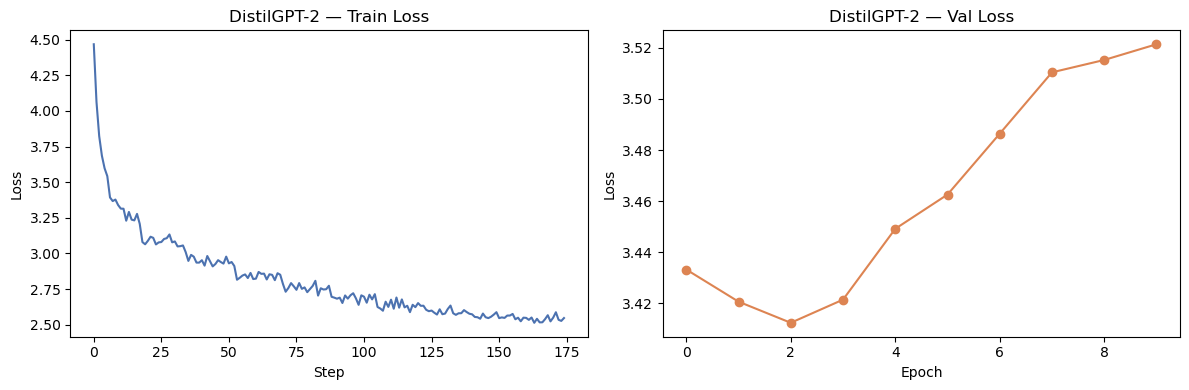

In [16]:
log_history       = trainer.state.log_history
gpt2_train_losses = [x["loss"]      for x in log_history if "loss" in x and "eval_loss" not in x]
gpt2_val_losses   = [x["eval_loss"] for x in log_history if "eval_loss" in x]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(gpt2_train_losses, color="#4C72B0")
axes[0].set_title("DistilGPT-2 — Train Loss"); axes[0].set_xlabel("Step"); axes[0].set_ylabel("Loss")
axes[1].plot(gpt2_val_losses, color="#DD8452", marker="o")
axes[1].set_title("DistilGPT-2 — Val Loss"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")
plt.tight_layout()
plt.savefig("figures/gpt2_training_curves.png", dpi=150)
plt.show()

## Section 7 — Inference Interface

Both models accept a free-text date (any format), a topic, and a sentiment. The date is normalised using the same function applied during training, ensuring the prompt format seen at inference matches what the model learned from.

In [17]:
# ── Load best checkpoints ─────────────────────────────────────────────────────
scratch_model.load_state_dict(torch.load("models/scratch/best_model.pt", map_location=DEVICE))
scratch_model.eval()
gpt2_model = gpt2_model.to(DEVICE)
gpt2_model.eval()
print("Both models loaded.")

Both models loaded.


In [18]:
VALID_SENTIMENTS = {"positive", "negative", "neutral"}

def build_prompt(date_raw: str, topic: str, sentiment: str = "neutral") -> str:
    assert sentiment in VALID_SENTIMENTS, f"sentiment must be one of {VALID_SENTIMENTS}"
    date_norm = normalise_date(date_raw)
    return f"[DATE: {date_norm}] [TOPIC: {topic}] [SENTIMENT: {sentiment}]"


def generate_scratch(date_raw, topic, sentiment="neutral", max_new_tokens=200,
                     temperature=0.9, top_k=50) -> str:
    prompt     = build_prompt(date_raw, topic, sentiment)
    prompt_ids = torch.tensor([tokenizer.encode(prompt).ids], dtype=torch.long).to(DEVICE)
    output_ids = scratch_model.generate(prompt_ids, max_new_tokens, temperature, top_k, EOE_ID)
    full_text  = tokenizer.decode(output_ids[0].tolist())
    return full_text[len(prompt):].replace("<|endofentry|>", "").strip()


def generate_gpt2(date_raw, topic, sentiment="neutral", max_new_tokens=200,
                  temperature=0.9, top_k=50) -> str:
    prompt  = build_prompt(date_raw, topic, sentiment)
    inputs  = gpt2_tokenizer(prompt, return_tensors="pt").to(DEVICE)
    eoe_tok = gpt2_tokenizer.convert_tokens_to_ids("<|endofentry|>")
    with torch.no_grad():
        output = gpt2_model.generate(
            **inputs, max_new_tokens=max_new_tokens,
            temperature=temperature, top_k=top_k, do_sample=True,
            pad_token_id=gpt2_tokenizer.eos_token_id, eos_token_id=eoe_tok
        )
    full_text = gpt2_tokenizer.decode(output[0], skip_special_tokens=False)
    return full_text[len(prompt):].replace("<|endofentry|>", "").strip()


def generate_both(date_raw, topic, sentiment="neutral", max_new_tokens=200):
    prompt = build_prompt(date_raw, topic, sentiment)
    print(f"PROMPT: {prompt}")
    print("=" * 70)
    s = generate_scratch(date_raw, topic, sentiment, max_new_tokens)
    g = generate_gpt2(date_raw, topic, sentiment, max_new_tokens)
    print("── FROM SCRATCH ──")
    print(s)
    print("── DISTILGPT-2  ──")
    print(g)
    return s, g

In [19]:
# ── Example generations across eras and sentiments ────────────────────────────
test_prompts = [
    ("March 14, 1847",    "death hunger voyage",         "negative"),
    ("January 1863",      "freedom escape plantation",   "positive"),
    ("le 3 octobre 1666", "mariage colonie hiver",        "neutral"),
    ("November 12, 1815", "fur trade rivalry hardship",  "negative"),
    ("August 1926",       "prairie farm harvest",        "positive"),
]

for date_raw, topic, sentiment in test_prompts:
    print("\n" + "#" * 70)
    generate_both(date_raw, topic, sentiment, max_new_tokens=150)


######################################################################
PROMPT: [DATE: March 14, 1847] [TOPIC: death hunger voyage] [SENTIMENT: negative]
── FROM SCRATCH ──
e ship. The captain has struck us and some people are safe, and they have been sent to prisoner with a crew in one side. Some say that they are fighting for nothing. Others are praying that they have all been safe and the doctor would strike the immigrant sheds against the ship. Some that they would never keep out of them with a foreigners. If they are safe and steal the little sheds, they cannot be. I keep out what I do, dear Diary. You are right to death. At least you can not read you and hear nothing. Is I not so dream? Why about Jasper? What if the other person is alive? Maybe that is why is that the first thing? I keep thinking of
── DISTILGPT-2  ──
I have never had a voyage again, but I have had to travel, every time in my life. This morning I was sick and my head was swollen. I was in my bedroom and my eyes w

## Section 8 — Evaluation

Three evaluation axes:
1. **Perplexity** on the held-out validation set (lower = better next-token prediction)
2. **Style metrics** on generated text vs. real entries — sentence length, lexical diversity, first-person rate
3. **Sentiment fidelity** — whether the `[SENTIMENT:]` token actually steers output sentiment, verified using the previous assignment's classifier

In [20]:
# ── 1. Perplexity ─────────────────────────────────────────────────────────────
def perplexity_scratch(model, loader, device):
    model.eval()
    total_loss, total_tok = 0.0, 0
    crit = nn.CrossEntropyLoss(reduction="sum", ignore_index=PAD_ID)
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            loss = crit(model(x).reshape(-1, tokenizer.get_vocab_size()), y.reshape(-1))
            total_loss += loss.item()
            total_tok  += (y != PAD_ID).sum().item()
    return math.exp(total_loss / total_tok)


def perplexity_gpt2(model, tokenizer, texts, device, max_len=128):
    model.eval()
    total_loss, total_tok = 0.0, 0
    with torch.no_grad():
        for text in texts:
            enc = tokenizer(text, return_tensors="pt", truncation=True, max_length=max_len).to(device)
            out = model(**enc, labels=enc["input_ids"].clone())
            n   = enc["input_ids"].shape[1]
            total_loss += out.loss.item() * n
            total_tok  += n
    return math.exp(total_loss / total_tok)


ppl_scratch = perplexity_scratch(scratch_model, val_loader, DEVICE)
ppl_gpt2    = perplexity_gpt2(gpt2_model, gpt2_tokenizer, val_entries["formatted"].tolist(), DEVICE)

print(f"Perplexity — From-Scratch: {ppl_scratch:.2f}")
print(f"Perplexity — DistilGPT-2:  {ppl_gpt2:.2f}")

Perplexity — From-Scratch: 123.04
Perplexity — DistilGPT-2:  31.10


In [21]:
# ── 2. Style metrics ──────────────────────────────────────────────────────────
import nltk
from nltk.tokenize import sent_tokenize, word_tokenize
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

FIRST_PERSON = {"i", "me", "my", "mine", "myself", "we", "our", "us"}

def style_metrics(text: str) -> dict:
    sents = sent_tokenize(text)
    words = [w for w in word_tokenize(text.lower()) if w.isalpha()]
    if not words or not sents:
        return {}
    return {
        "avg_sentence_len":  len(words) / len(sents),
        "type_token_ratio":  len(set(words)) / len(words),
        "first_person_rate": sum(1 for w in words if w in FIRST_PERSON) / len(words),
    }


eval_prompts = [
    ("March 14, 1847",  "death hunger voyage",        "negative"),
    ("January 1863",    "freedom escape",             "positive"),
    ("November 1815",   "winter cold hardship",       "negative"),
    ("August 1926",     "farm prairie harvest",       "positive"),
    ("October 1666",    "marriage colony winter",     "neutral"),
    ("July 1783",       "war loyalist journey",       "neutral"),
    ("February 1847",   "grief loss family",          "negative"),
    ("September 1863",  "hope arrival canada",        "positive"),
    ("December 1815",   "snow fur trade danger",      "negative"),
    ("May 1926",        "loneliness homesick england","neutral"),
]

s_metrics, g_metrics = [], []
for date_raw, topic, sentiment in eval_prompts:
    s_metrics.append(style_metrics(generate_scratch(date_raw, topic, sentiment, 200)))
    g_metrics.append(style_metrics(generate_gpt2(date_raw, topic, sentiment, 200)))

ref_metrics = pd.DataFrame([style_metrics(t) for t in val_entries["entry_text"].tolist()]).mean()

metrics_df = pd.DataFrame({
    "From-Scratch": pd.DataFrame(s_metrics).mean(),
    "DistilGPT-2":  pd.DataFrame(g_metrics).mean(),
    "Reference":    ref_metrics,
}).round(3)

display(metrics_df)

,From-Scratch,DistilGPT-2,Reference
avg_sentence_len,12.460,17.153,12.593
type_token_ratio,0.704,0.634,0.632
first_person_rate,0.080,0.071,0.060


In [22]:
# ── 3. Sentiment fidelity ─────────────────────────────────────────────────────
# Generate pairs of entries with opposite sentiments from the same prompt,
# then use the saved sentiment scores to check whether conditioning worked.
# We use the same score columns already loaded from the previous assignment.

# NOTE: swap in your actual classifier predict function here if preferred.
# This section uses the aggregate Positive_score / Negative_score difference
# from the saved CSVs as a proxy — or replace with a live classifier call.

fidelity_prompts = [
    ("March 1847",   "hunger cold ship"),
    ("January 1863", "freedom family journey"),
    ("August 1926",  "prairie farm work"),
]

print("Sentiment Fidelity — Positive vs Negative conditioning")
print("=" * 60)
print("(Inspect outputs manually — does [SENTIMENT: negative] produce")
print(" darker, more sorrowful language than [SENTIMENT: positive]?)\n")

for date_raw, topic in fidelity_prompts:
    print(f"PROMPT: {build_prompt(date_raw, topic, 'positive')}")
    print("POSITIVE →", generate_gpt2(date_raw, topic, "positive", max_new_tokens=80))
    print(f"\nPROMPT: {build_prompt(date_raw, topic, 'negative')}")
    print("NEGATIVE →", generate_gpt2(date_raw, topic, "negative", max_new_tokens=80))
    print("-" * 60)

Sentiment Fidelity — Positive vs Negative conditioning
(Inspect outputs manually — does [SENTIMENT: negative] produce
 darker, more sorrowful language than [SENTIMENT: positive]?)

PROMPT: [DATE: March 1847] [TOPIC: hunger cold ship] [SENTIMENT: positive]
POSITIVE → Our captain is sick and tired, and I do not want to go again when the cold is beginning to get much worse. He is almost gone, but Papa and Lucy have moved to the nearby town where they can camped. She is worried about his fever and heartache, and I am afraid he is afraid that their hut isn’t as safe as home. We stay here and there

PROMPT: [DATE: March 1847] [TOPIC: hunger cold ship] [SENTIMENT: negative]
NEGATIVE → , the cold inside me is so cold and cold inside that I have never seen it. I do not have a heart ache. And yet, in the afternoon The heat inside me is so cold that I can hardly stand the heat inside! The ship must be loaded to sea soon. They cannot carry passengers! We are staying on deck at the berth. They will

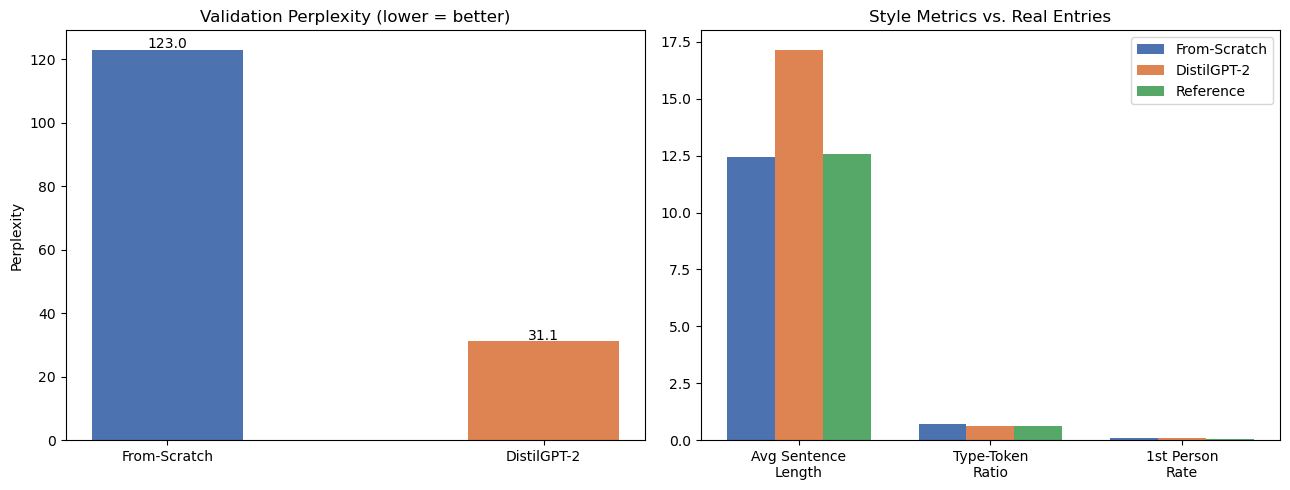

In [23]:
# ── Summary figures ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Perplexity
bars = axes[0].bar(["From-Scratch", "DistilGPT-2"], [ppl_scratch, ppl_gpt2],
                   color=["#4C72B0", "#DD8452"], width=0.4)
axes[0].set_title("Validation Perplexity (lower = better)")
axes[0].set_ylabel("Perplexity")
for bar, v in zip(bars, [ppl_scratch, ppl_gpt2]):
    axes[0].text(bar.get_x() + bar.get_width()/2, v + 0.5, f"{v:.1f}", ha="center")

# Style metrics
style_cols = ["avg_sentence_len", "type_token_ratio", "first_person_rate"]
x, w = np.arange(len(style_cols)), 0.25
axes[1].bar(x - w, metrics_df.loc[style_cols, "From-Scratch"], w, label="From-Scratch", color="#4C72B0")
axes[1].bar(x,     metrics_df.loc[style_cols, "DistilGPT-2"],  w, label="DistilGPT-2",  color="#DD8452")
axes[1].bar(x + w, metrics_df.loc[style_cols, "Reference"],    w, label="Reference",    color="#55A868")
axes[1].set_xticks(x)
axes[1].set_xticklabels(["Avg Sentence\nLength", "Type-Token\nRatio", "1st Person\nRate"])
axes[1].set_title("Style Metrics vs. Real Entries")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/evaluation_summary.png", dpi=150)
plt.show()

In [24]:
# ── Qualitative comparison table ──────────────────────────────────────────────
report_prompts = [
    ("March 14, 1847",  "death hunger voyage",       "negative"),
    ("January 1863",    "freedom escape plantation", "positive"),
    ("November 1815",   "winter fur trade rivalry",  "neutral"),
]

print("QUALITATIVE COMPARISON")
print("=" * 70)
for date_raw, topic, sentiment in report_prompts:
    prompt = build_prompt(date_raw, topic, sentiment)
    s_out  = generate_scratch(date_raw, topic, sentiment, 150)
    g_out  = generate_gpt2(date_raw, topic, sentiment, 150)
    print(f"\nPROMPT: {prompt}")
    print("─" * 30 + " FROM SCRATCH " + "─" * 26)
    print(s_out)
    print("─" * 30 + " DISTILGPT-2  " + "─" * 26)
    print(g_out)
    print("=" * 70)

QUALITATIVE COMPARISON

PROMPT: [DATE: March 14, 1847] [TOPIC: death hunger voyage] [SENTIMENT: negative]
────────────────────────────── FROM SCRATCH ──────────────────────────
looked frantic too. Someone had ordered me to make me stay ashore on deck at where the ship was buried in the stupor above deck. Da was trying to find him, but I asked if he would speak to me as later. In such case there were a woman who was there. He told me that Da had struck to find her position in his condition that he must not permit him to take the authorities. “He is ill to see how it is,” Michael ordered. “He’s just as well as a matter as well. The first place will be taken, and he will be more difficult than a stranger. I am sure he needs this decision,” he said. “Perhaps he needs assistance, I
────────────────────────────── DISTILGPT-2  ──────────────────────────
The British have sent to the New World to kill their people. They are so cruel. Their families are hungry and all those they cannot bear, and